# Project – Part 1: Segmentation by classification
## Leaf Disease Segmentation dataset

**Task:** binary segmentation. Every pixel is either **disease (1)** or **not disease (0)**; healthy leaf tissue
*and* the image background are both class 0.

**Idea:** we turn segmentation into the *classification* problem we studied in the image-classification lab.
Each pixel is one *instance*; its *features* describe the pixel (1.1) or a small patch around it (1.2, 1.3); its
*label* is read from the mask. We train a classifier on pixels sampled from the training images, then apply it
to **every** pixel of a test image: the predicted labels form a segmentation mask.

This mirrors the three approaches of the lecture *Introduction to Image Classification*, applied per pixel:

| Section | Features of one pixel | Classifiers | Course material used |
|---|---|---|---|
| 1.1 | its RGB (and HSV) values | kNN, logistic regression | lab 02 (RGB, HSV), lab 08 (kNN) |
| 1.2a | raw 15×15 RGB patch (675 values) | kNN, logistic regression, random forest | lab 08 ex. 1 (raw pixels as features) |
| 1.2b | hand-crafted patch features | kNN, LR, RF, MLP | lab 04 (box filter, Sobel), lab 08 ex. 2.5 (mean/variance features) |
| 1.2 ext. | post-processing of the predicted mask | – | lab 05 (thresholding, connected components) |
| 1.3 | raw patch | Keras MLP and CNN | lab 08 ex. 3 + CNN trailer |

Machine learning beyond the labs (allowed by the assignment): logistic regression, random forest, ROC curve /
AUC, feature scaling, early stopping, IoU / Dice.

## Preparation

In [1]:
import matplotlib.pyplot as plt

# plots directly in the notebook
%matplotlib inline

# make figures larger (reduce if figures are too wide for your screen)
plt.rcParams["figure.figsize"] = (7,7)

# if you have a high-dpi monitor
#%config InlineBackend.figure_format = 'retina'

import ipywidgets as widgets

In [2]:
import time
import pathlib
import numpy as np
import pandas as pd
import scipy
import scipy.ndimage
import skimage
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
import skimage.measure
import skimage.morphology
import sklearn
import sklearn.neighbors
import sklearn.linear_model
import sklearn.ensemble
import sklearn.neural_network
import sklearn.preprocessing
import sklearn.pipeline
import sklearn.metrics
import seaborn as sns
import matplotlib.patches as patches

In [3]:
# Folder where you unzipped the Kaggle download; the first folder that exists is used
candidates = [pathlib.Path("leaf_disease_segmentation"),           # next to this notebook
              pathlib.Path("../leaf_disease_segmentation"),
              pathlib.Path("../datasets/leaf_disease_segmentation")]
ddir = next((p for p in candidates if p.exists()), candidates[0])
print(f"We expect the data files in directory {ddir.absolute()}")
assert ddir.exists(), "Dataset not found: unzip it next to this notebook, or add its folder to `candidates`"

IMG_SHAPE = (200, 300)   # (rows, columns): every image and mask is resized to this shape
PATCH = 15               # side of the square patch around each pixel (1.2 and 1.3)
N_PER_IMG = 50           # random pixels sampled from every image (as in the assignment)
N_SEG_EVAL = 30          # number of full test images used to compute mean IoU / Dice
CLASS_NAMES = ["no disease", "disease"]
np.random.seed(0)        # same random choices every time we run the notebook

We expect the data files in directory C:\Users\kevin\PycharmProjects\pythonProjectRiz24\project_leaf_disease_detection\leaf_disease_segmentation


## 0. The data
### 0.1 What is in the folder?

In [4]:
def list_images(folder):
    """Sorted list of the image files in a folder"""
    return [f for f in sorted(folder.iterdir()) if f.suffix.lower() in (".jpg", ".jpeg", ".png")]

for sub in ["orig_data", "aug_data"]:
    for folder in ["train_images", "train_masks", "valid_images", "valid_masks"]:
        d = ddir/sub/folder
        if d.exists():
            files = list_images(d)
            print(f"{sub}/{folder}: {len(files)} files, e.g. {[f.name for f in files[:3]]}")

orig_data/train_images: 498 files, e.g. ['00002.jpg', '00003.jpg', '00004.jpg']
orig_data/train_masks: 498 files, e.g. ['00002.png', '00003.png', '00004.png']
orig_data/valid_images: 90 files, e.g. ['00000.jpg', '00001.jpg', '00007.jpg']
orig_data/valid_masks: 90 files, e.g. ['00000.png', '00001.png', '00007.png']
aug_data/train_images: 2500 files, e.g. ['00000_1.jpg', '00000_2.jpg', '00000_4.jpg']
aug_data/train_masks: 2500 files, e.g. ['00000_1.png', '00000_2.png', '00000_4.png']
aug_data/valid_images: 440 files, e.g. ['00000_0.jpg', '00000_3.jpg', '00001_2.jpg']
aug_data/valid_masks: 440 files, e.g. ['00000_0.png', '00000_3.png', '00001_2.png']


There are two versions of the data:
- `orig_data`: 498 training and 90 validation photos, each leaf once;
- `aug_data`: 5 augmented copies (rotated, flipped, ...) of **every** original photo, named `<original>_<k>`.
  498 + 90 = 588 originals × 5 = 2940 = 2500 + 440 files.

The cell below shows that `aug_data/train_images` contains copies of leaves that are in the official
**validation** set, which we use as our **test** set. Training on `aug_data` would let the model see rotated copies
of the test leaves, and the test scores would be too optimistic (*data leakage*). In addition, `aug_data` masks
are grayscale with disease = 38 instead of red. **We use only `orig_data`.**

In [5]:
def leaf_name(fn):
    """'00002_3' -> '00002': name of the original photo an augmented file was made from"""
    return fn.stem.split("_")[0]

odir = ddir/"orig_data"
if (ddir/"aug_data").exists():
    test_leaves = {f.stem for f in list_images(odir/"valid_images")}
    aug_train_leaves = {leaf_name(f) for f in list_images(ddir/"aug_data"/"train_images")}
    print(f"{len(test_leaves & aug_train_leaves)} of the {len(test_leaves)} test leaves "
          f"have augmented copies in aug_data/train_images")

90 of the 90 test leaves have augmented copies in aug_data/train_images


### 0.2 One image and its mask

image: (236, 350, 3) uint8
mask:  (236, 350, 3) uint8 values: [  0 128]


[Text(0.5, 1.0, 'mask as stored in the file'), [], []]

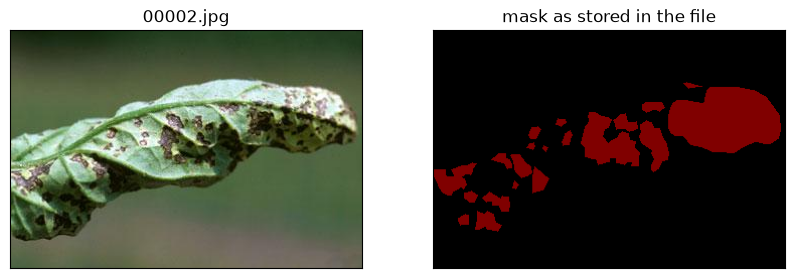

In [6]:
fn = list_images(odir/"train_images")[0]
im = skimage.io.imread(fn)
m = skimage.io.imread(odir/"train_masks"/(fn.stem + ".png"))
print("image:", im.shape, im.dtype)
print("mask: ", m.shape, m.dtype, "values:", np.unique(m))

fig, axs = plt.subplots(ncols=2, figsize=(10,4))
axs[0].imshow(im)
axs[0].set(title=fn.name, xticks=[], yticks=[])
axs[1].imshow(m)
axs[1].set(title="mask as stored in the file", xticks=[], yticks=[])

The mask is read as an RGB image: disease is red `(128, 0, 0)`, everything else is black. As in the binarization
lab, we get a binary mask by **thresholding**: a pixel is diseased if its brightest channel is > 0.

### 0.3 Image sizes
The photos do not all have the same size. To store them in one numpy array we resize all images and masks to
`IMG_SHAPE` (as in lab 02, with `skimage.transform.resize`). `IMG_SHAPE` has about the same width/height ratio as
the photos, so leaves are barely distorted.

rows: 150-3264 px, columns: 94-4160 px


[Text(0.5, 0, 'width [px]'),
 Text(0, 0.5, 'height [px]'),
 Text(0.5, 1.0, 'Original image sizes')]

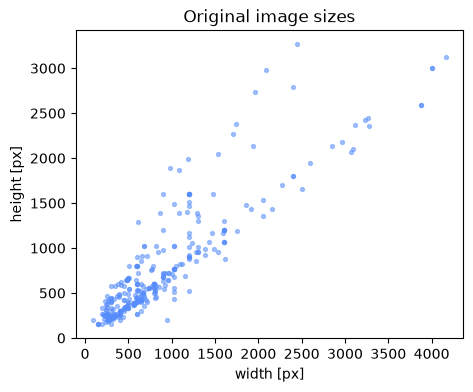

In [7]:
fns_tr = list_images(odir/"train_images")
fns_te = list_images(odir/"valid_images")
sizes = np.array([skimage.io.imread(f).shape[:2] for f in fns_tr + fns_te])   # (rows, columns)
print(f"rows: {sizes[:,0].min()}-{sizes[:,0].max()} px, columns: {sizes[:,1].min()}-{sizes[:,1].max()} px")

fig, ax = plt.subplots(figsize=(5,4))
ax.scatter(sizes[:,1], sizes[:,0], s=8, alpha=0.5)
ax.set(xlabel="width [px]", ylabel="height [px]", title="Original image sizes")

### 0.4 Load everything, and split into training / validation / test
- **test** = the official `valid_images` (90 photos): only used for the final numbers;
- **training / validation** = a random split of the official `train_images`; validation is used to choose
  hyper-parameters (k in kNN, patch size, threshold, ...).

We split by **image**, not by pixel: pixels of the same leaf are very similar, so having pixels of one leaf both in
training and in test would give over-optimistic results.

In [8]:
def load_pair(fn_im, fn_mask):
    """Read an image and its mask and resize both to IMG_SHAPE.
    Returns the image as uint8 (rows, cols, 3) and the mask as bool (rows, cols), True = disease."""
    im = skimage.io.imread(fn_im)
    if im.ndim == 2:                       # grayscale photo -> 3 identical channels
        im = skimage.color.gray2rgb(im)
    im = im[:,:,:3]                        # drop the alpha channel, if any
    m = skimage.io.imread(fn_mask)
    if m.ndim == 3:                        # RGB mask -> brightest channel
        m = m[:,:,:3].max(axis=2)
    mask = m > 0
    # photo: smooth interpolation; mask: nearest neighbour (order=0), so it stays exactly 0/1
    im = skimage.img_as_ubyte(skimage.transform.resize(im, IMG_SHAPE, anti_aliasing=True))
    mask = skimage.transform.resize(mask.astype(float), IMG_SHAPE, order=0, anti_aliasing=False) > 0.5
    return im, mask


def load_set(im_folder, mask_folder):
    ims, masks, names = [], [], []
    for fn in list_images(odir/im_folder):
        fn_mask = odir/mask_folder/(fn.stem + ".png")
        if not fn_mask.exists():
            print("No mask for", fn.name)
            continue
        im, mask = load_pair(fn, fn_mask)
        ims.append(im)
        masks.append(mask)
        names.append(fn.stem)
    return np.array(ims), np.array(masks), names


ims_pool, masks_pool, names_pool = load_set("train_images", "train_masks")
ims_te, masks_te, names_te = load_set("valid_images", "valid_masks")

perm = np.random.permutation(len(ims_pool))
n_va = int(0.15 * len(perm))
ix_va, ix_tr = np.sort(perm[:n_va]), np.sort(perm[n_va:])
ims_tr, masks_tr = ims_pool[ix_tr], masks_pool[ix_tr]
ims_va, masks_va = ims_pool[ix_va], masks_pool[ix_va]
names_tr = [names_pool[i] for i in ix_tr]
names_va = [names_pool[i] for i in ix_va]
del ims_pool, masks_pool

print("Training images:  ", ims_tr.shape, masks_tr.shape)
print("Validation images:", ims_va.shape, masks_va.shape)
print("Test images:      ", ims_te.shape, masks_te.shape)
pd.DataFrame({name: {"images": len(m),
                     "diseased pixels": f"{m.mean()*100:.1f}%",
                     "images without disease": int(np.sum(m.max(axis=(1,2)) == 0))}
              for name, m in [("training", masks_tr), ("validation", masks_va), ("test", masks_te)]}).T

Training images:   (424, 200, 300, 3) (424, 200, 300)
Validation images: (74, 200, 300, 3) (74, 200, 300)
Test images:       (90, 200, 300, 3) (90, 200, 300)


,images,diseased pixels,images without disease
training,424,16.6%,0
validation,74,15.0%,0
test,90,16.1%,0


### 0.5 Look at the data
`overlay` paints the mask in red on top of the image (as the sky exercise of lab 02).

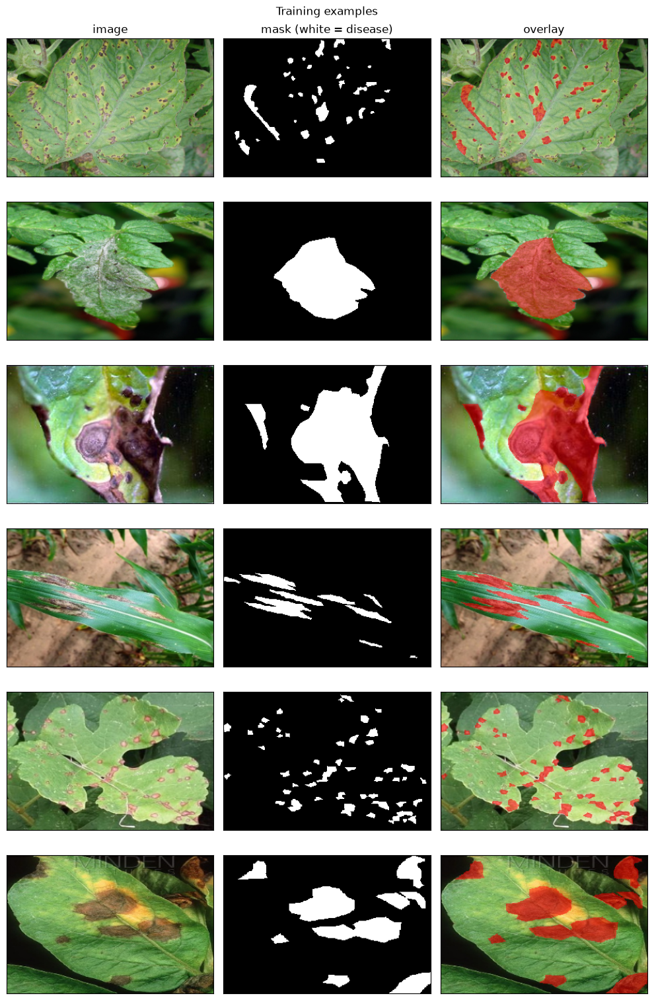

In [9]:
def overlay(im, mask, color=(1,0,0), alpha=0.5):
    """Float copy of im where the pixels in mask are mixed with color"""
    out = skimage.img_as_float(im).copy()
    out[mask] = (1-alpha) * out[mask] + alpha * np.array(color)
    return out


def show_examples(ims, masks, idx, title=None):
    """One row per image: image | mask | overlay"""
    fig, axs = plt.subplots(nrows=len(idx), ncols=3, figsize=(10, 2.6*len(idx)))
    axs = np.array(axs).reshape(len(idx), 3)
    for row, i in zip(axs, idx):
        row[0].imshow(ims[i])
        row[1].imshow(masks[i], cmap="gray", vmin=0, vmax=1)
        row[2].imshow(overlay(ims[i], masks[i]))
        for ax in row:
            ax.set(xticks=[], yticks=[])
    axs[0,0].set_title("image"); axs[0,1].set_title("mask (white = disease)"); axs[0,2].set_title("overlay")
    if title:
        fig.suptitle(title)
    fig.tight_layout()

show_examples(ims_tr, masks_tr, np.random.choice(len(ims_tr), 6, replace=False), "Training examples")

In [ ]:
# Browse all training images with a slider
# @widgets.interact(i=(0, len(ims_tr)-1))
# def f(i=0):
#     show_examples(ims_tr, masks_tr, [i], names_tr[i])
#     plt.show()
from IPython.display import display

out = widgets.Output()
slider = widgets.IntSlider(value=0, min=0, max=len(ims_tr)-1, description="i")

def update(change=None):
    with out:
        out.clear_output(wait=True)
        i = slider.value
        show_examples(ims_tr, masks_tr, [i], names_tr[i])
        plt.show()

slider.observe(update, names="value")
display(slider, out)
update()

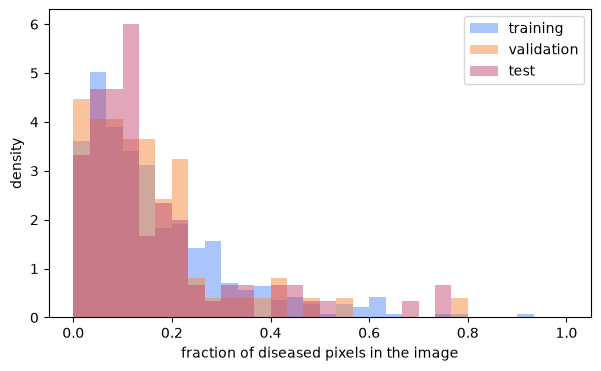

In [11]:
# How much of each image is diseased? Small values = strong class imbalance
fig, ax = plt.subplots(figsize=(7,4))
for name, m in [("training", masks_tr), ("validation", masks_va), ("test", masks_te)]:
    ax.hist(m.mean(axis=(1,2)), bins=30, range=(0,1), alpha=0.5, density=True, label=name)
ax.set(xlabel="fraction of diseased pixels in the image", ylabel="density")
ax.legend()

Colour of diseased vs. other pixels, in RGB and in **HSV** (lab 02: hue, saturation, value). This is a preview of
what the pixel classifier of 1.1 will see.

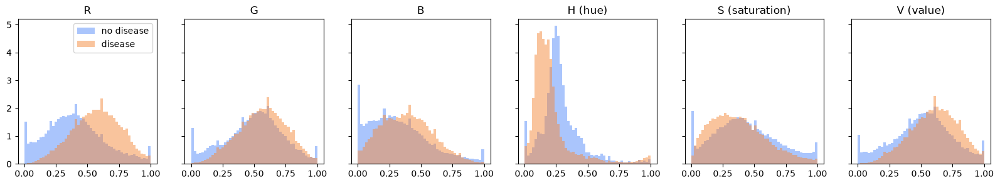

In [12]:
pix = ims_tr.reshape(-1, 3)[::97] / 255            # every 97th pixel, to be fast
lab = masks_tr.reshape(-1)[::97]
hsv = skimage.color.rgb2hsv(pix[:, np.newaxis, :])[:, 0, :]
channels = [pix[:,0], pix[:,1], pix[:,2], hsv[:,0], hsv[:,1], hsv[:,2]]

fig, axs = plt.subplots(ncols=6, figsize=(20,3), sharey=True)
for ax, vals, name in zip(axs, channels, ["R", "G", "B", "H (hue)", "S (saturation)", "V (value)"]):
    ax.hist(vals[~lab], bins=50, range=(0,1), density=True, alpha=0.5, label=CLASS_NAMES[0])
    ax.hist(vals[lab], bins=50, range=(0,1), density=True, alpha=0.5, label=CLASS_NAMES[1])
    ax.set(title=name)
axs[0].legend()

### Evaluation helpers
- `evaluate`: per-pixel accuracy, AUC, F1, ROC curve and confusion matrix (heatmap as in lab 08);
- `iou_dice`: Intersection over Union and Dice of a whole predicted mask, the standard segmentation metrics;
- `record`: stores the results of every experiment in `results`, to compare all models at the end.

In [13]:
def evaluate(y_true, p, title, threshold=0.5):
    """y_true: true labels (0/1); p: predicted probability of disease."""
    y_pred = (p >= threshold).astype(int)
    acc = np.mean(y_pred == y_true)
    auc = sklearn.metrics.roc_auc_score(y_true, p)
    cm = sklearn.metrics.confusion_matrix(y_true=y_true, y_pred=y_pred, labels=[0,1])

    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(11,4))
    fpr, tpr, _ = sklearn.metrics.roc_curve(y_true, p)
    ax1.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    ax1.plot([0,1], [0,1], "k--", lw=0.8)
    ax1.set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
    ax1.legend()
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, ax=ax2)
    ax2.set(xlabel="predicted", ylabel="true",
            title=f"Confusion matrix on {len(y_true)} pixels (acc={acc*100:.1f}%)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def iou_dice(mask_true, mask_pred):
    """IoU and Dice of the disease class for one image"""
    inter = np.sum(mask_true & mask_pred)
    union = np.sum(mask_true | mask_pred)
    total = np.sum(mask_true) + np.sum(mask_pred)
    iou = inter / union if union > 0 else 1.0      # nothing to find and nothing found: perfect
    dice = 2 * inter / total if total > 0 else 1.0
    return iou, dice


def eval_segmentation(segment_fn, threshold=0.5, ims=None, masks=None, n=N_SEG_EVAL):
    """Mean IoU and Dice of segment_fn(image) -> probability map, over the first n test images"""
    ims = ims_te if ims is None else ims
    masks = masks_te if masks is None else masks
    scores = [iou_dice(masks[i], segment_fn(ims[i]) >= threshold) for i in range(min(n, len(ims)))]
    return np.mean([s[0] for s in scores]), np.mean([s[1] for s in scores])


results = []

def record(part, name, p_va, p_te, segment_fn=None, train_time=None):
    """Stores validation/test pixel metrics (+ IoU/Dice on full test images if segment_fn is given)"""
    row = {"part": part, "model": name,
           "val AUC": sklearn.metrics.roc_auc_score(y_va, p_va),
           "test AUC": sklearn.metrics.roc_auc_score(y_te, p_te),
           "test accuracy": np.mean((p_te >= 0.5) == y_te),
           "test F1": sklearn.metrics.f1_score(y_te, (p_te >= 0.5).astype(int)),
           "train time [s]": train_time}
    if segment_fn is not None:
        t = time.time()
        row["test mIoU"], row["test Dice"] = eval_segmentation(segment_fn)
        row["seconds per image"] = (time.time() - t) / min(N_SEG_EVAL, len(ims_te))
    results.append(row)
    return pd.DataFrame([row]).round(3)

In [14]:
def show_predictions(segment_fn, idx, title="", threshold=0.5):
    """One row per test image: image | ground truth | P(disease) | prediction"""
    fig, axs = plt.subplots(nrows=len(idx), ncols=4, figsize=(14, 2.6*len(idx)))
    axs = np.array(axs).reshape(len(idx), 4)
    for row, i in zip(axs, idx):
        p = segment_fn(ims_te[i])
        iou, dice = iou_dice(masks_te[i], p >= threshold)
        row[0].imshow(ims_te[i])
        row[0].set_title(names_te[i])
        row[1].imshow(masks_te[i], cmap="gray", vmin=0, vmax=1)
        row[1].set_title("ground truth")
        row[2].imshow(p, cmap="viridis", vmin=0, vmax=1)
        row[2].set_title("P(disease)")
        row[3].imshow(overlay(ims_te[i], p >= threshold))
        row[3].set_title(f"prediction, IoU={iou:.2f}")
        for ax in row:
            ax.set(xticks=[], yticks=[])
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def explore_predictions(segment_fn):
    """Interactive version: choose the test image and the threshold with sliders"""
    @widgets.interact(i=(0, len(ims_te)-1), threshold=(0.05, 0.95, 0.05))
    def f(i=0, threshold=0.5):
        show_predictions(segment_fn, [i], threshold=threshold)


# test images shown in the figures: from little to much disease
order = np.argsort(masks_te.mean(axis=(1,2)))
SHOW_IDX = list(order[np.linspace(0, len(order)-1, 5).astype(int)])

## 1.1 Pixel classifier on the RGB values

From every image we choose `N_PER_IMG` random pixels. The features of a pixel are its 3 RGB values (in [0,1]);
its label is the value of the mask at the same position. Same for validation and test.

In [15]:
def sample_pixels(masks, n_per_img, pos_fraction=None):
    """Choose n_per_img random pixels in every image.
    Returns 3 arrays: image index, row and column of every chosen pixel.
    pos_fraction=0.5: half of the pixels are chosen among diseased pixels (only for training, see 1.2)"""
    ii, rr, cc = [], [], []
    for i in range(len(masks)):
        r = np.random.randint(0, masks.shape[1], n_per_img)
        c = np.random.randint(0, masks.shape[2], n_per_img)
        if pos_fraction is not None and masks[i].any():
            n_pos = int(pos_fraction * n_per_img)
            pos_r, pos_c = np.nonzero(masks[i])           # coordinates of all diseased pixels
            k = np.random.randint(0, len(pos_r), n_pos)
            r[:n_pos], c[:n_pos] = pos_r[k], pos_c[k]
        ii.append(np.full(n_per_img, i))
        rr.append(r)
        cc.append(c)
    return np.concatenate(ii), np.concatenate(rr), np.concatenate(cc)


def labels_at(masks, pix):
    ii, rr, cc = pix
    return masks[ii, rr, cc].astype(int)


def rgb_at(ims, pix):
    """Features of 1.1: the RGB values of the pixel, in [0,1]"""
    ii, rr, cc = pix
    return ims[ii, rr, cc] / 255


def hsv_at(ims, pix):
    """Same pixels in the HSV colour space (lab 02)"""
    return skimage.color.rgb2hsv(rgb_at(ims, pix)[:, np.newaxis, :])[:, 0, :]


pix_tr = sample_pixels(masks_tr, N_PER_IMG)
pix_va = sample_pixels(masks_va, N_PER_IMG)
pix_te = sample_pixels(masks_te, N_PER_IMG)
y_tr, y_va, y_te = labels_at(masks_tr, pix_tr), labels_at(masks_va, pix_va), labels_at(masks_te, pix_te)
X_tr, X_va, X_te = rgb_at(ims_tr, pix_tr), rgb_at(ims_va, pix_va), rgb_at(ims_te, pix_te)
H_tr, H_va, H_te = hsv_at(ims_tr, pix_tr), hsv_at(ims_va, pix_va), hsv_at(ims_te, pix_te)

print("Training data and labels with shapes:", X_tr.shape, y_tr.shape)
print("Testing data and labels with shapes: ", X_te.shape, y_te.shape)
print(f"Fraction of diseased training pixels: {y_tr.mean():.3f}")
print(f"A classifier that always answers 'no disease' has test accuracy {1 - y_te.mean():.3f}")

Training data and labels with shapes: (21200, 3) (21200,)
Testing data and labels with shapes:  (4500, 3) (4500,)
Fraction of diseased training pixels: 0.165
A classifier that always answers 'no disease' has test accuracy 0.837


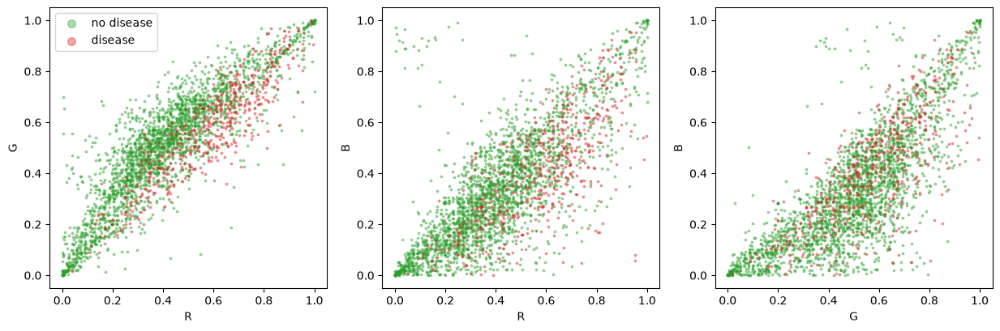

In [16]:
# The problem in colour space (3000 random training pixels)
sub = np.random.choice(len(X_tr), min(3000, len(X_tr)), replace=False)
fig, axs = plt.subplots(ncols=3, figsize=(15,4.5))
for ax, (a, b) in zip(axs, [(0,1), (0,2), (1,2)]):
    for cls, color in [(0, "tab:green"), (1, "tab:red")]:
        s = sub[y_tr[sub] == cls]
        ax.scatter(X_tr[s,a], X_tr[s,b], s=3, alpha=0.4, c=color, label=CLASS_NAMES[cls])
    ax.set(xlabel="RGB"[a], ylabel="RGB"[b])
axs[0].legend(markerscale=4)

### kNN: choose *k* on the validation set
As in lab 08 (exercise 2.4), we study how the result changes with the number of neighbours. We choose *k* on the
**validation** set, never on the test set. We look at AUC rather than accuracy, because accuracy is dominated by the
majority class.

k=   1  validation AUC=0.618  accuracy=0.787
k=   5  validation AUC=0.757  accuracy=0.832
k=  15  validation AUC=0.801  accuracy=0.843
k=  25  validation AUC=0.818  accuracy=0.842
k=  51  validation AUC=0.830  accuracy=0.841
k= 101  validation AUC=0.835  accuracy=0.843
k= 201  validation AUC=0.836  accuracy=0.849
Best k: 201


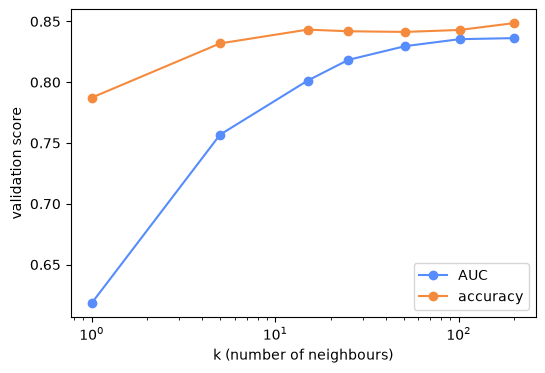

In [17]:
ks = [1, 5, 15, 25, 51, 101, 201]
aucs, accs = [], []
for k in ks:
    clf = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_tr, y_tr)
    p = clf.predict_proba(X_va)[:,1]
    aucs.append(sklearn.metrics.roc_auc_score(y_va, p))
    accs.append(np.mean((p >= 0.5) == y_va))
    print(f"k={k:4d}  validation AUC={aucs[-1]:.3f}  accuracy={accs[-1]:.3f}")
k_best = ks[int(np.argmax(aucs))]
print("Best k:", k_best)

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(ks, aucs, "o-", label="AUC")
ax.plot(ks, accs, "o-", label="accuracy")
ax.set(xscale="log", xlabel="k (number of neighbours)", ylabel="validation score")
ax.legend()

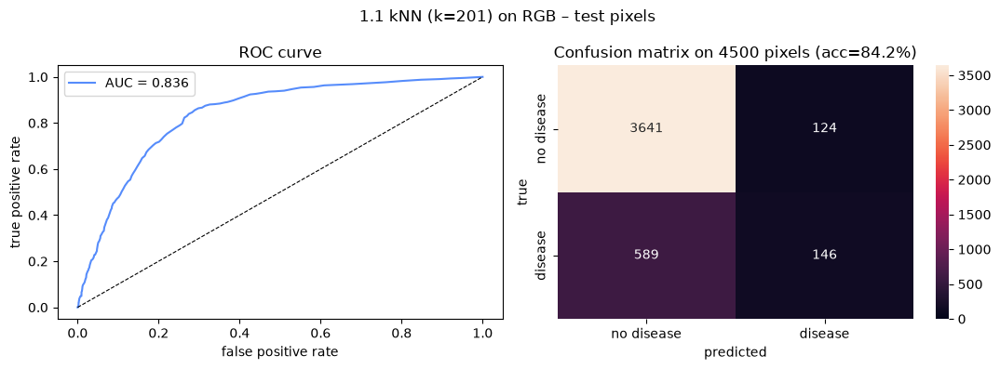

,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.1,"kNN k=201, RGB",0.836,0.836,0.842,0.291,0.028,0.138,0.203,4.903


In [18]:
def segment_pixels(clf, im, space="rgb"):
    """Apply a pixel classifier to every pixel of an image -> map of P(disease)"""
    if space == "hsv":
        X = skimage.color.rgb2hsv(im).reshape(-1, 3)
    else:
        X = im.reshape(-1, 3) / 255
    return clf.predict_proba(X)[:,1].reshape(im.shape[:2])


t = time.time()
knn_rgb = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k_best)
knn_rgb.fit(X_tr, y_tr)
train_time = time.time() - t
p_te = knn_rgb.predict_proba(X_te)[:,1]
evaluate(y_te, p_te, f"1.1 kNN (k={k_best}) on RGB – test pixels")
record("1.1", f"kNN k={k_best}, RGB", knn_rgb.predict_proba(X_va)[:,1], p_te,
       lambda im: segment_pixels(knn_rgb, im), train_time)

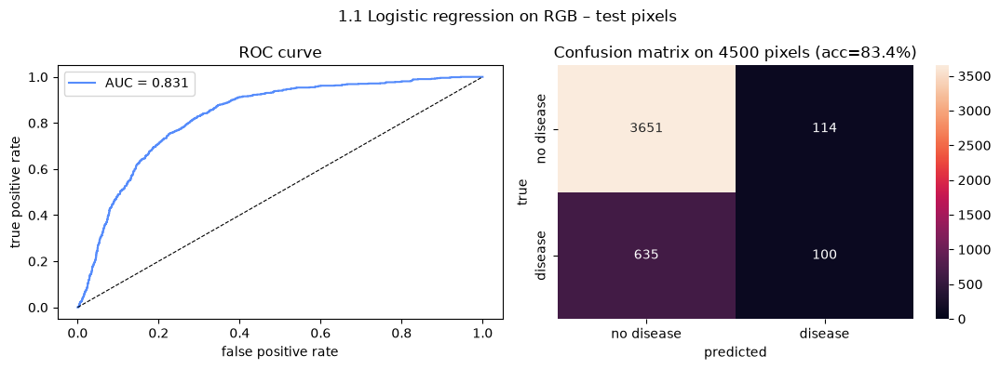

,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.1,"LogReg, RGB",0.821,0.831,0.834,0.211,0.06,0.104,0.158,0.007


In [19]:
# Logistic regression: a linear classifier (the "simple linear classifier" of the lecture)
t = time.time()
lr_rgb = sklearn.linear_model.LogisticRegression(max_iter=1000)
lr_rgb.fit(X_tr, y_tr)
train_time = time.time() - t
p_te = lr_rgb.predict_proba(X_te)[:,1]
evaluate(y_te, p_te, "1.1 Logistic regression on RGB – test pixels")
record("1.1", "LogReg, RGB", lr_rgb.predict_proba(X_va)[:,1], p_te,
       lambda im: segment_pixels(lr_rgb, im), train_time)

**Extension: HSV instead of RGB.** In lab 02 we said that thresholding hue and saturation is better for colour
segmentation than thresholding R, G, B. Does the same hold for a classifier? (Careful: hue is an angle, so 0.99 and
0.01 are actually very close colours, but for kNN they are far apart.)

In [20]:
t = time.time()
knn_hsv = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k_best)
knn_hsv.fit(H_tr, y_tr)
train_time = time.time() - t
p_te = knn_hsv.predict_proba(H_te)[:,1]
record("1.1", f"kNN k={k_best}, HSV", knn_hsv.predict_proba(H_va)[:,1], p_te,
       lambda im: segment_pixels(knn_hsv, im, "hsv"), train_time)

,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.1,"kNN k=201, HSV",0.833,0.834,0.839,0.26,0.024,0.137,0.205,5.242


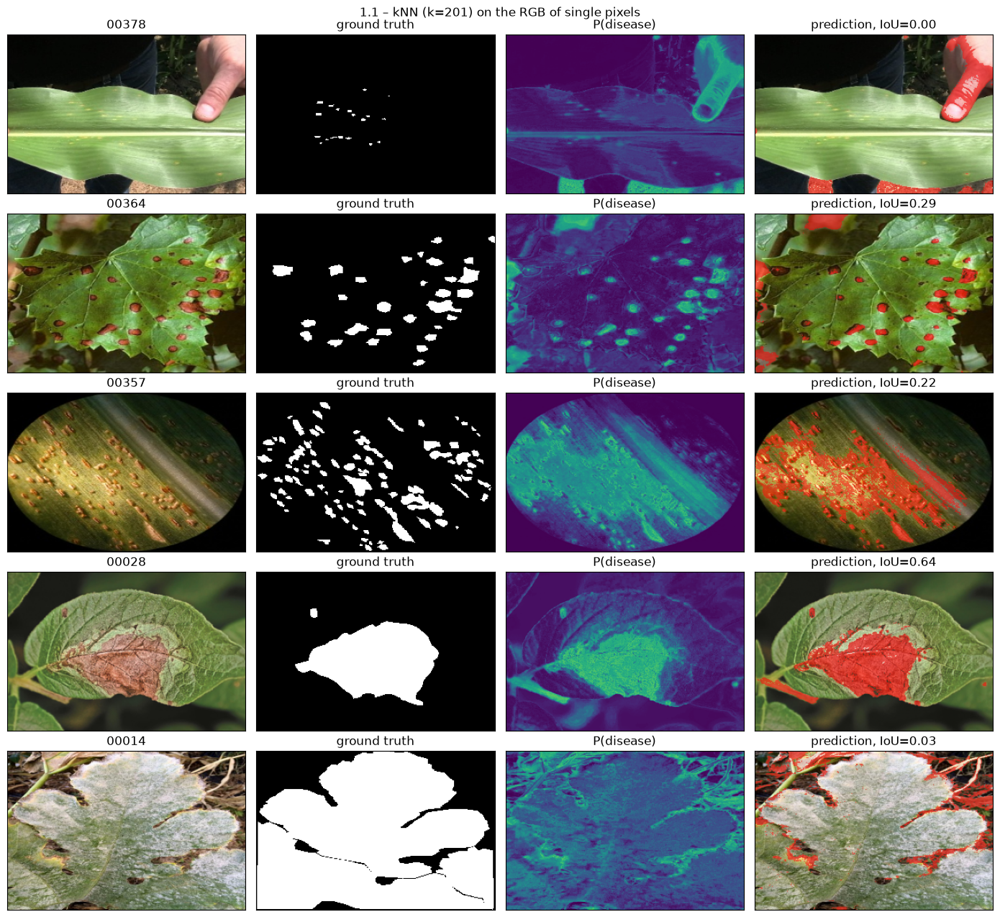

In [21]:
# Apply the classifier to EVERY pixel of some test images -> segmentation
show_predictions(lambda im: segment_pixels(knn_rgb, im), SHOW_IDX, f"1.1 – kNN (k={k_best}) on the RGB of single pixels")

In [22]:
explore_predictions(lambda im: segment_pixels(knn_rgb, im))

interactive(children=(IntSlider(value=0, description='i', max=89), FloatSlider(value=0.5, description='thresho…

**Questions for the report (1.1)**
- Is accuracy a good metric here? Compare it with the "always no disease" baseline printed above.
- Which pixels are wrong? (brown/yellow background, shadows, veins, dry leaf edges, ...)
- Why does the colour of a single pixel fundamentally limit the result? → motivates using a neighbourhood (1.2).

## 1.2 Patch classifiers
Now the classifier sees the `PATCH × PATCH` window centred on the pixel (the *neighbourhood*, as in local filtering,
lab 04). The label is still the class of the central pixel. Images are padded by reflection, so pixels near the
border also get a full patch.

### 1.2a Raw patch values as features
As in exercise 1 of lab 08 (nearest neighbour on raw pixel values), the features are the raw values of the patch:
15·15·3 = 675 numbers.

In [23]:
def extract_patches(ims, pix, size=PATCH):
    """Cut the size x size patch centred on every chosen pixel -> (n, size, size, 3) floats in [0,1]"""
    ii, rr, cc = pix
    r = size // 2
    padded = np.pad(ims, ((0,0), (r,r), (r,r), (0,0)), mode="reflect")
    patches_ = np.zeros((len(ii), size, size, 3), dtype=np.float32)
    for j in range(len(ii)):
        # pixel (row, col) of the image is pixel (row+r, col+r) of the padded image,
        # so its patch starts at (row, col) in the padded image
        patches_[j] = padded[ii[j], rr[j]:rr[j]+size, cc[j]:cc[j]+size]
    return patches_ / 255


def image_patches(im, size=PATCH, stride=1):
    """All patches of one image -> (n_rows, n_cols, size, size, 3).
    With stride > 1 we only take every stride-th row and column (much faster)."""
    r = size // 2
    padded = np.pad(im, ((r,r), (r,r), (0,0)), mode="reflect")
    H, W = im.shape[:2]
    out = np.zeros((len(range(0, H, stride)), len(range(0, W, stride)), size, size, 3), dtype=np.float32)
    for dr in range(size):          # fill position (dr, dc) of all patches at once
        for dc in range(size):
            out[:, :, dr, dc, :] = padded[dr:dr+H:stride, dc:dc+W:stride]
    return out / 255


def predict_disease(clf, X):
    """P(disease) for every row of X, both for sklearn and for keras models"""
    if hasattr(clf, "predict_proba"):
        return clf.predict_proba(X)[:,1]
    return clf.predict(X, batch_size=4096, verbose=0)[:,1]     # keras: softmax with 2 outputs


def segment_patches(clf, im, flatten=True, stride=2, size=PATCH):
    """Classify the patch around every stride-th pixel; the map is then resized to the full image"""
    P = image_patches(im, size, stride)
    n_rows, n_cols = P.shape[:2]
    P = P.reshape(n_rows * n_cols, size, size, 3)
    X = P.reshape(len(P), -1) if flatten else P
    p = predict_disease(clf, X).reshape(n_rows, n_cols)
    if stride > 1:
        p = skimage.transform.resize(p, im.shape[:2], order=1)
    return p


P_tr, P_va, P_te = extract_patches(ims_tr, pix_tr), extract_patches(ims_va, pix_va), extract_patches(ims_te, pix_te)
Xp_tr, Xp_va, Xp_te = P_tr.reshape(len(P_tr), -1), P_va.reshape(len(P_va), -1), P_te.reshape(len(P_te), -1)
print("patches:", P_tr.shape, "-> flattened:", Xp_tr.shape)

# check: both functions cut the same patches
assert np.allclose(image_patches(ims_te[0])[pix_te[1][0], pix_te[2][0]], P_te[0])

patches: (21200, 15, 15, 3) -> flattened: (21200, 675)


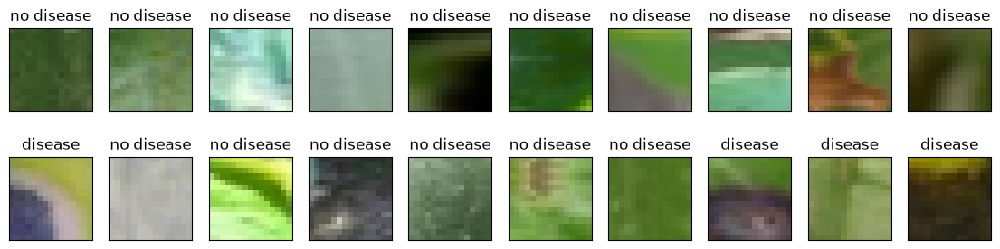

In [24]:
# Some training patches with their label
fig, axs = plt.subplots(nrows=2, ncols=10, figsize=(14,3.4))
for ax, j in zip(axs.flatten(), np.random.choice(len(P_tr), 20, replace=False)):
    ax.imshow(P_tr[j])
    ax.set(title=CLASS_NAMES[y_tr[j]], xticks=[], yticks=[])

In [25]:
# kNN on raw patches (lab 08, exercise 1). Only pixel metrics: classifying all 60000 pixels of an image
# by comparing each 675-value patch with ~20000 training patches would take minutes per image.
for k in [5, 25, 51]:
    clf = sklearn.neighbors.KNeighborsClassifier(n_neighbors=k).fit(Xp_tr, y_tr)
    print(f"k={k}: validation AUC {sklearn.metrics.roc_auc_score(y_va, clf.predict_proba(Xp_va)[:,1]):.3f}")

t = time.time()
knn_raw = sklearn.neighbors.KNeighborsClassifier(n_neighbors=25).fit(Xp_tr, y_tr)
train_time = time.time() - t
record("1.2a", "kNN k=25, raw patch", knn_raw.predict_proba(Xp_va)[:,1], knn_raw.predict_proba(Xp_te)[:,1],
       None, train_time)

k=5: validation AUC 0.702
k=25: validation AUC 0.779
k=51: validation AUC 0.797


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s]
0,1.2a,"kNN k=25, raw patch",0.779,0.774,0.842,0.11,0.023


Logistic regression and random forest. For logistic regression we first *standardize* each feature (subtract its
mean, divide by its standard deviation, with `StandardScaler`); this helps the optimizer.

In [26]:
raw_classifiers = {
    "LogReg, raw patch": sklearn.pipeline.make_pipeline(
        sklearn.preprocessing.StandardScaler(),
        sklearn.linear_model.LogisticRegression(max_iter=2000, C=0.1)),
    "RandomForest, raw patch": sklearn.ensemble.RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0),
}
for name, clf in raw_classifiers.items():
    t = time.time()
    clf.fit(Xp_tr, y_tr)
    train_time = time.time() - t
    display(record("1.2a", name, clf.predict_proba(Xp_va)[:,1], clf.predict_proba(Xp_te)[:,1],
                   lambda im, clf=clf: segment_patches(clf, im), train_time))

,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2a,"LogReg, raw patch",0.811,0.814,0.839,0.283,2.641,0.148,0.225,0.132


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2a,"RandomForest, raw patch",0.872,0.87,0.85,0.3,9.194,0.149,0.224,0.244


### 1.2b Hand-crafted patch features
As in exercise 2.5 of lab 08 we compute a few meaningful features instead of using raw values. For each pixel:
- its R, G, B and H, S, V values;
- the **mean** and **standard deviation** of R, G, B in the patch;
- the mean and standard deviation of the **gradient magnitude** (Sobel, lab 04) in the patch: texture and edges;
- the mean saturation in the patch.

→ 15 features. They are computed as filter responses on the whole image, so one image takes milliseconds:
- the mean over the patch is a **box filter** (lab 04);
- the standard deviation comes from $\text{std} = \sqrt{\text{mean}(x^2) - \text{mean}(x)^2}$.

`scipy.ndimage.uniform_filter` gives exactly the same result as convolving with a box kernel, but much faster
(the cell below checks it).

In [27]:
SOBEL_H = np.array([[-1, 0, +1],
                    [-2, 0, +2],
                    [-1, 0, +1]])
SOBEL_V = SOBEL_H.T

def local_mean(a, size):
    """Mean of a over the size x size window centred on every pixel (box filter)"""
    return scipy.ndimage.uniform_filter(a, size=size, mode="reflect")

# check: same result as the box-filter convolution of lab 04
a = skimage.img_as_float(ims_te[0][:,:,1])
k = np.full((PATCH, PATCH), 1/(PATCH*PATCH))
print("Same result as convolving with a box kernel:",
      np.allclose(scipy.ndimage.convolve(a, k[::-1,::-1], mode="reflect"), local_mean(a, PATCH)))

Same result as convolving with a box kernel: True


In [28]:
FEATURE_NAMES = (["R", "G", "B", "H", "S", "V"]
                 + ["mean R", "mean G", "mean B", "std R", "std G", "std B"]
                 + ["mean gradient", "std gradient", "mean S"])


def feature_map(im, size=PATCH):
    """Features of every pixel of an image -> (rows, cols, 15)"""
    im = skimage.img_as_float(im)
    hsv = skimage.color.rgb2hsv(im)
    gray = skimage.color.rgb2gray(im)
    gh = scipy.ndimage.convolve(gray, SOBEL_H[::-1,::-1], mode="reflect")
    gv = scipy.ndimage.convolve(gray, SOBEL_V[::-1,::-1], mode="reflect")
    grad = (gh**2 + gv**2) ** 0.5                            # gradient magnitude (lab 04)

    maps = [im[:,:,0], im[:,:,1], im[:,:,2], hsv[:,:,0], hsv[:,:,1], hsv[:,:,2]]
    means = [local_mean(im[:,:,c], size) for c in range(3)]
    stds = [np.sqrt(np.clip(local_mean(im[:,:,c]**2, size) - means[c]**2, 0, None)) for c in range(3)]
    grad_mean = local_mean(grad, size)
    grad_std = np.sqrt(np.clip(local_mean(grad**2, size) - grad_mean**2, 0, None))
    maps += means + stds + [grad_mean, grad_std, local_mean(hsv[:,:,1], size)]
    return np.stack(maps, axis=2).astype(np.float32)


def features_at(ims, pix, size=PATCH):
    """Features of the chosen pixels (computes one feature map per image)"""
    ii, rr, cc = pix
    F = np.zeros((len(ii), len(FEATURE_NAMES)), dtype=np.float32)
    for i in np.unique(ii):
        sel = ii == i
        F[sel] = feature_map(ims[i], size)[rr[sel], cc[sel]]
    return F


def segment_features(clf, im, size=PATCH):
    fm = feature_map(im, size)
    return clf.predict_proba(fm.reshape(-1, fm.shape[2]))[:,1].reshape(im.shape[:2])


F_tr, F_va, F_te = features_at(ims_tr, pix_tr), features_at(ims_va, pix_va), features_at(ims_te, pix_te)
print("features:", F_tr.shape)

features: (21200, 15)


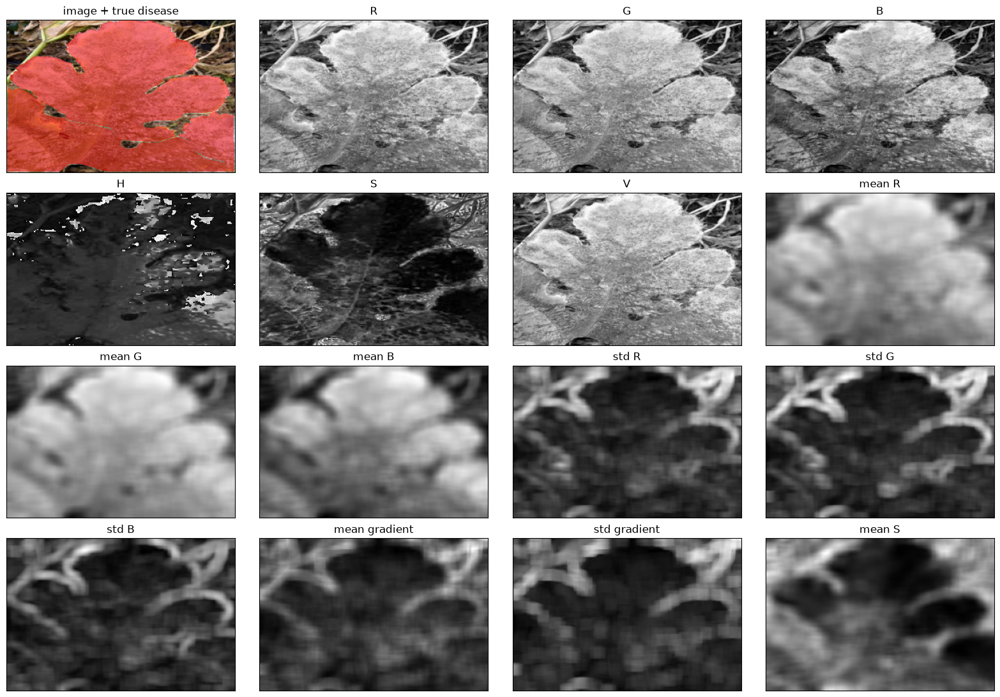

In [29]:
# What do the features look like on one test image?
i = SHOW_IDX[-1]
fm = feature_map(ims_te[i])
fig, axs = plt.subplots(nrows=4, ncols=4, figsize=(16,11))
axs = axs.flatten()
axs[0].imshow(overlay(ims_te[i], masks_te[i]))
axs[0].set(title="image + true disease", xticks=[], yticks=[])
for ax, f, name in zip(axs[1:], range(fm.shape[2]), FEATURE_NAMES):
    ax.imshow(fm[:,:,f], cmap="gray")
    ax.set(title=name, xticks=[], yticks=[])
fig.tight_layout()

In [30]:
feature_classifiers = {
    "kNN k=25, features": sklearn.pipeline.make_pipeline(
        sklearn.preprocessing.StandardScaler(),
        sklearn.neighbors.KNeighborsClassifier(n_neighbors=25)),
    "LogReg, features": sklearn.pipeline.make_pipeline(
        sklearn.preprocessing.StandardScaler(),
        sklearn.linear_model.LogisticRegression(max_iter=2000)),
    "RandomForest, features": sklearn.ensemble.RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0),
    "MLP (sklearn), features": sklearn.pipeline.make_pipeline(
        sklearn.preprocessing.StandardScaler(),
        sklearn.neural_network.MLPClassifier((64, 32), max_iter=300, early_stopping=True, random_state=0)),
}
for name, clf in feature_classifiers.items():
    t = time.time()
    clf.fit(F_tr, y_tr)
    train_time = time.time() - t
    # kNN: no full-image segmentation, comparing 60000 pixels with all training pixels is too slow
    segment_fn = None if name.startswith("kNN") else (lambda im, clf=clf: segment_features(clf, im))
    display(record("1.2b", name, clf.predict_proba(F_va)[:,1], clf.predict_proba(F_te)[:,1],
                   segment_fn, train_time))

,part,model,val AUC,test AUC,test accuracy,test F1,train time [s]
0,1.2b,"kNN k=25, features",0.875,0.877,0.866,0.478,0.103


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2b,"LogReg, features",0.877,0.866,0.848,0.396,0.117,0.256,0.365,0.053


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2b,"RandomForest, features",0.893,0.889,0.872,0.508,1.854,0.267,0.38,0.19


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2b,"MLP (sklearn), features",0.906,0.901,0.876,0.589,7.239,0.362,0.488,0.061


[Text(0.5, 1.0, 'Random forest feature importance'),
 Text(0.5, 0, 'importance')]

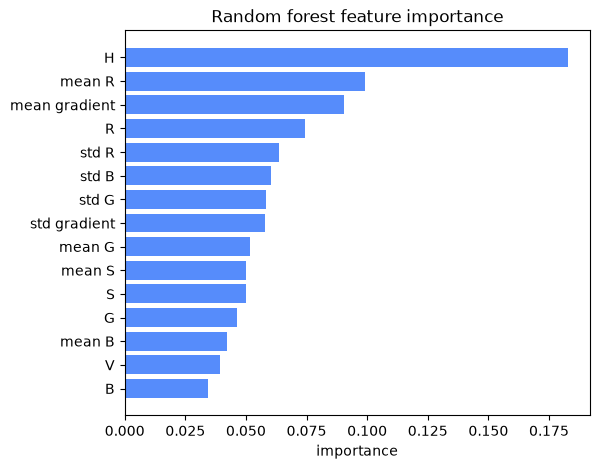

In [31]:
# Which features matter? (random forest feature importance)
rf_feat = feature_classifiers["RandomForest, features"]
order_f = np.argsort(rf_feat.feature_importances_)
fig, ax = plt.subplots(figsize=(6,5))
ax.barh(np.array(FEATURE_NAMES)[order_f], rf_feat.feature_importances_[order_f])
ax.set(title="Random forest feature importance", xlabel="importance")

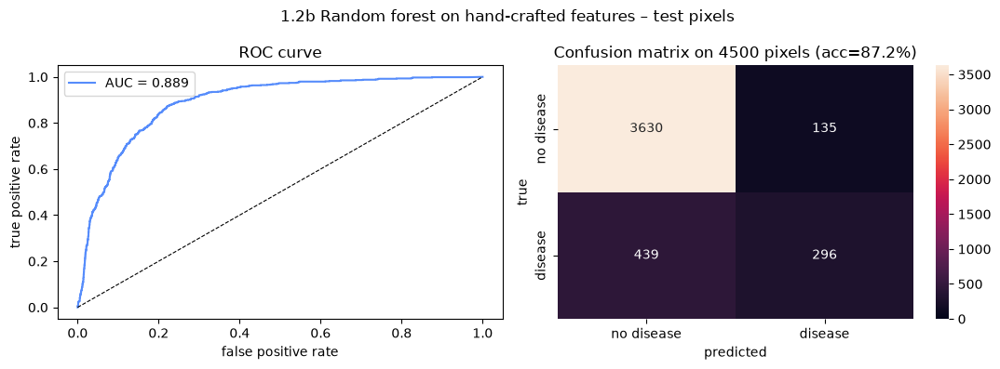

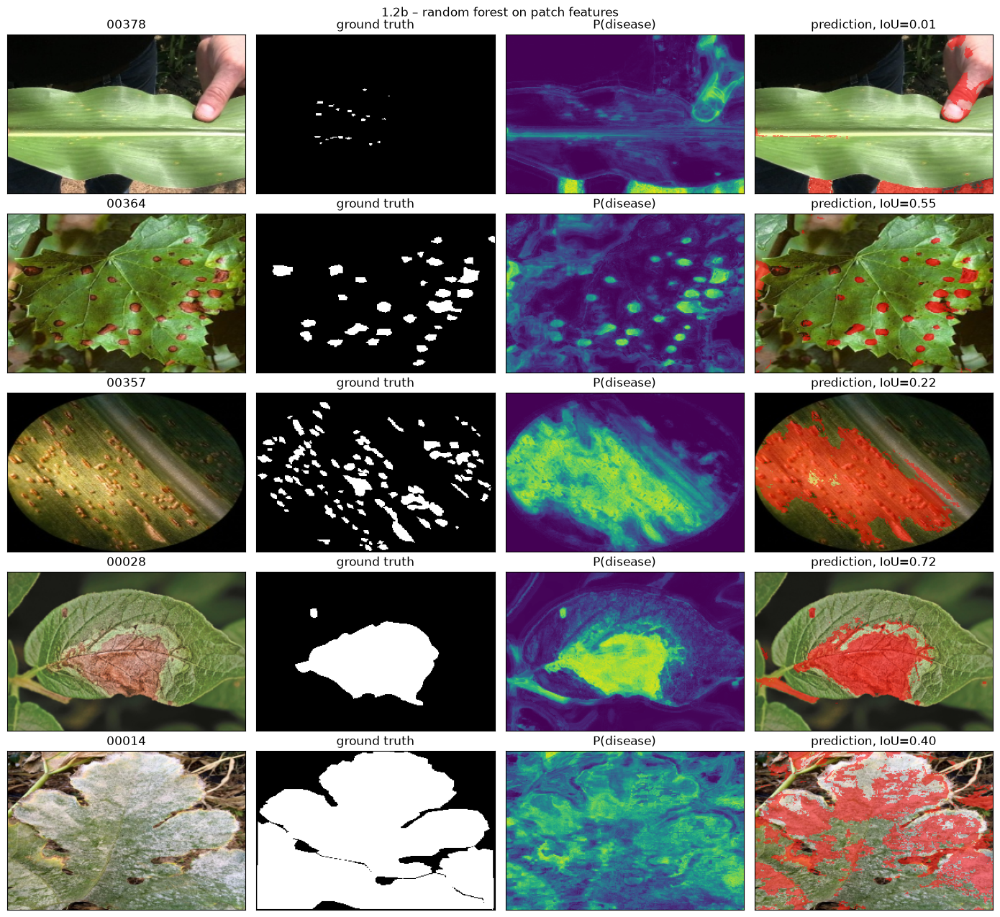

In [32]:
evaluate(y_te, rf_feat.predict_proba(F_te)[:,1], "1.2b Random forest on hand-crafted features – test pixels")
show_predictions(lambda im: segment_features(rf_feat, im), SHOW_IDX, "1.2b – random forest on patch features")

In [33]:
explore_predictions(lambda im: segment_features(rf_feat, im))

interactive(children=(IntSlider(value=0, description='i', max=89), FloatSlider(value=0.5, description='thresho…

### 1.2 Extensions
**(i) Patch size.** A larger window sees more context, but blurs the boundaries of the lesions. We choose it on the
validation set.

patch  5x5 : validation AUC = 0.888
patch  9x9 : validation AUC = 0.889
patch 15x15: validation AUC = 0.894
patch 25x25: validation AUC = 0.893
patch 41x41: validation AUC = 0.888


[Text(0.5, 0, 'patch size [px]'),
 Text(0, 0.5, 'validation AUC'),
 Text(0.5, 1.0, 'Random forest on features')]

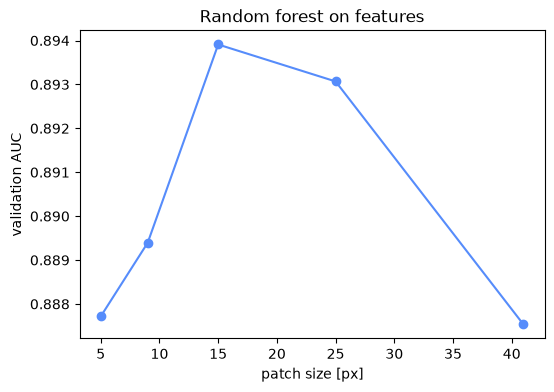

In [34]:
sizes_p = [5, 9, 15, 25, 41]
aucs_p = []
for size in sizes_p:
    Fa, Fb = features_at(ims_tr, pix_tr, size), features_at(ims_va, pix_va, size)
    clf = sklearn.ensemble.RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=0)
    clf.fit(Fa, y_tr)
    aucs_p.append(sklearn.metrics.roc_auc_score(y_va, clf.predict_proba(Fb)[:,1]))
    print(f"patch {size:2d}x{size:<2d}: validation AUC = {aucs_p[-1]:.3f}")

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(sizes_p, aucs_p, "o-")
ax.set(xlabel="patch size [px]", ylabel="validation AUC", title="Random forest on features")

**(ii) Class imbalance.** Diseased pixels are a minority, so a uniformly sampled training set contains few of them.
Two remedies:
- choose half of the *training* pixels among diseased pixels (`pos_fraction=0.5`);
- choose the decision threshold on the validation set instead of using 0.5.

Validation and test stay uniformly sampled, so the metrics still reflect the true class proportions.

In [35]:
pix_trb = sample_pixels(masks_tr, N_PER_IMG, pos_fraction=0.5)
y_trb, F_trb = labels_at(masks_tr, pix_trb), features_at(ims_tr, pix_trb)
print(f"Balanced training set: {y_trb.mean()*100:.1f}% diseased (uniform sampling: {y_tr.mean()*100:.1f}%)")

t = time.time()
rf_bal = sklearn.ensemble.RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0)
rf_bal.fit(F_trb, y_trb)
train_time = time.time() - t
record("1.2b", "RandomForest, features, balanced sampling", rf_bal.predict_proba(F_va)[:,1],
       rf_bal.predict_proba(F_te)[:,1], lambda im: segment_features(rf_bal, im), train_time)

Balanced training set: 57.9% diseased (uniform sampling: 16.5%)


,part,model,val AUC,test AUC,test accuracy,test F1,train time [s],test mIoU,test Dice,seconds per image
0,1.2b,"RandomForest, features, balanced sampling",0.904,0.886,0.763,0.548,1.868,0.382,0.516,0.17


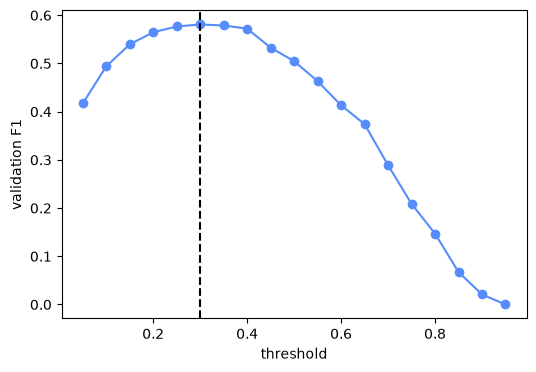

Best threshold 0.30: test F1 0.604 (threshold 0.5: 0.508)
Test mIoU at the best threshold: 0.401


In [36]:
# Threshold chosen on VALIDATION to maximise F1, then reported on test
p_va = rf_feat.predict_proba(F_va)[:,1]
p_te = rf_feat.predict_proba(F_te)[:,1]
thresholds = np.linspace(0.05, 0.95, 19)
f1s = [sklearn.metrics.f1_score(y_va, (p_va >= t).astype(int)) for t in thresholds]
best_thr = thresholds[int(np.argmax(f1s))]

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(thresholds, f1s, "o-")
ax.axvline(best_thr, ls="--", c="k")
ax.set(xlabel="threshold", ylabel="validation F1")
plt.show()

print(f"Best threshold {best_thr:.2f}: test F1 {sklearn.metrics.f1_score(y_te, (p_te >= best_thr).astype(int)):.3f} "
      f"(threshold 0.5: {sklearn.metrics.f1_score(y_te, (p_te >= 0.5).astype(int)):.3f})")
miou, mdice = eval_segmentation(lambda im: segment_features(rf_feat, im), threshold=best_thr)
print(f"Test mIoU at the best threshold: {miou:.3f}")

**(iii) Post-processing with the tools of the binarization lab.** A pixel classifier decides every pixel
independently, so the predicted mask is noisy. As in lab 05:
1. smooth the probability map (`skimage.filters.gaussian`, lab 04);
2. threshold it;
3. find the connected components (`skimage.measure.label`) and remove those smaller than `minsize` pixels.

Careful: lesions can be tiny, so a too large `minsize` also removes true lesions. First explore the parameters
interactively (as in exercise 1 of lab 05), then choose them on the **validation** images.

In [37]:
def postprocess(p, sigma=2, threshold=0.5, minsize=20):
    """Smooth, binarize, keep only connected components with at least minsize pixels"""
    if sigma > 0:
        p = skimage.filters.gaussian(p, sigma=sigma)
    mask = p >= threshold
    labels = skimage.measure.label(mask)
    areas = np.bincount(labels.flatten())     # area of every connected component (label 0 = background)
    keep = areas >= minsize
    keep[0] = False
    return keep[labels]


probs_va = [segment_features(rf_feat, im) for im in ims_va]       # computed once, reused below

@widgets.interact(i=(0, len(ims_va)-1), sigma=(0, 6, 0.5), threshold=(0.05, 0.95, 0.05), minsize=(0, 300, 10))
def f(i=0, sigma=2, threshold=0.5, minsize=20):
    raw = probs_va[i] >= 0.5
    post = postprocess(probs_va[i], sigma, threshold, minsize)
    fig, axs = plt.subplots(ncols=3, figsize=(14,3.5))
    axs[0].imshow(overlay(ims_va[i], masks_va[i]))
    axs[0].set_title("ground truth")
    axs[1].imshow(overlay(ims_va[i], raw))
    axs[1].set_title(f"threshold 0.5, IoU={iou_dice(masks_va[i], raw)[0]:.2f}")
    axs[2].imshow(overlay(ims_va[i], post))
    axs[2].set_title(f"post-processed, IoU={iou_dice(masks_va[i], post)[0]:.2f}")
    for ax in axs:
        ax.set(xticks=[], yticks=[])
    plt.show()

interactive(children=(IntSlider(value=0, description='i', max=73), FloatSlider(value=2.0, description='sigma',…

In [38]:
# Grid search on the VALIDATION images
best_params, best_iou = None, -1
for sigma in [0, 1, 2, 4]:
    for threshold in [0.3, 0.4, 0.5]:
        for minsize in [0, 20, 100]:
            miou = np.mean([iou_dice(m, postprocess(p, sigma, threshold, minsize))[0]
                            for p, m in zip(probs_va, masks_va)])
            if miou > best_iou:
                best_params, best_iou = (sigma, threshold, minsize), miou
print(f"Validation mIoU without post-processing: {np.mean([iou_dice(m, p >= 0.5)[0] for p, m in zip(probs_va, masks_va)]):.3f}")
print(f"Best (sigma, threshold, minsize) = {best_params}, validation mIoU {best_iou:.3f}")

# ... and the result on TEST
miou_raw, dice_raw = eval_segmentation(lambda im: segment_features(rf_feat, im))
miou_post, dice_post = eval_segmentation(lambda im: postprocess(segment_features(rf_feat, im), *best_params))
print(f"Test mIoU: {miou_raw:.3f} -> with post-processing: {miou_post:.3f}")
results.append({"part": "1.2b", "model": "RandomForest, features + post-processing",
                "test mIoU": miou_post, "test Dice": dice_post})

Validation mIoU without post-processing: 0.284
Best (sigma, threshold, minsize) = (1, 0.3, 0), validation mIoU 0.385
Test mIoU: 0.267 -> with post-processing: 0.410


With connected components we can also *count* the lesions and draw their bounding boxes, exactly as we did for the
coins in lab 05.

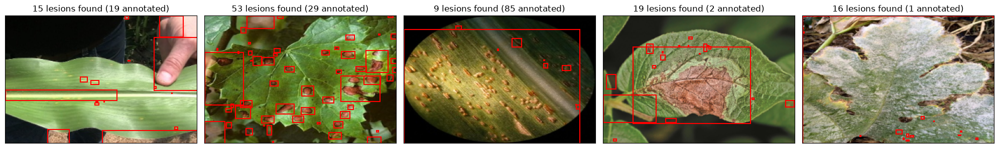

In [39]:
fig, axs = plt.subplots(ncols=len(SHOW_IDX), figsize=(4*len(SHOW_IDX), 3.5))
for ax, i in zip(axs, SHOW_IDX):
    mask = postprocess(segment_features(rf_feat, ims_te[i]), *best_params)
    regions = skimage.measure.regionprops(skimage.measure.label(mask))
    ax.imshow(ims_te[i])
    for r in regions:
        (min_row, min_col, max_row, max_col) = r.bbox
        rect = patches.Rectangle((min_col, min_row), max_col - min_col, max_row - min_row,
                                 linewidth=1.5, edgecolor="r", facecolor="none")
        ax.add_patch(rect)
    n_true = skimage.measure.label(masks_te[i]).max()
    ax.set(title=f"{len(regions)} lesions found ({n_true} annotated)", xticks=[], yticks=[])
fig.tight_layout()

## 1.3 Neural networks on patches (Keras)
As in lab 08:
- **MLP** (densely connected network): the input is the flattened patch (675 values);
- **CNN**: the input is the patch as a 15×15×3 array; convolutional and max-pooling layers exploit its spatial
  structure.

As in the lab, the output layer has one neuron per class with a softmax, and the labels are one-hot encoded with
`keras.utils.to_categorical`. Neural networks like more data, so we sample more pixels per image.

In [40]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Conv2D, MaxPooling2D, Flatten, Dropout, RandomFlip

N_PER_IMG_NN = 100
pix_nn_tr = sample_pixels(masks_tr, N_PER_IMG_NN)
pix_nn_va = sample_pixels(masks_va, N_PER_IMG_NN)
yn_tr, yn_va = labels_at(masks_tr, pix_nn_tr), labels_at(masks_va, pix_nn_va)
Pn_tr, Pn_va = extract_patches(ims_tr, pix_nn_tr), extract_patches(ims_va, pix_nn_va)

# Convert labels to categorical one-hot encoding
yn_tr_oh = keras.utils.to_categorical(yn_tr, num_classes=2)
yn_va_oh = keras.utils.to_categorical(yn_va, num_classes=2)
print("Training patches for the networks:", Pn_tr.shape, yn_tr_oh.shape)


def train(model, X, y_oh, Xv, yv_oh, epochs=30):
    """Train with early stopping: stop when the validation loss has not improved for 4 epochs,
    and keep the weights of the best epoch"""
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    t = time.time()
    history = model.fit(X, y_oh, epochs=epochs, batch_size=256,
                        validation_data=(Xv, yv_oh), callbacks=[stop], verbose=2)
    train_time = time.time() - t

    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(11,3.5))
    for key, ax in [("loss", ax1), ("accuracy", ax2)]:
        ax.plot(history.history[key], label="training")
        ax.plot(history.history["val_" + key], label="validation")
        ax.set(xlabel="epoch", title=key)
        ax.legend()
    plt.show()
    return train_time

ModuleNotFoundError: No module named 'tensorflow.python'

In [ ]:
mlp = Sequential()
mlp.add(keras.Input(shape=(PATCH*PATCH*3,)))
mlp.add(Dense(256))
mlp.add(Activation("relu"))
mlp.add(Dropout(0.3))
mlp.add(Dense(64))
mlp.add(Activation("relu"))
mlp.add(Dense(2))
mlp.add(Activation("softmax"))
mlp.summary()

train_time = train(mlp, Pn_tr.reshape(len(Pn_tr), -1), yn_tr_oh, Pn_va.reshape(len(Pn_va), -1), yn_va_oh)
p_te = predict_disease(mlp, Xp_te)
evaluate(y_te, p_te, "1.3 Keras MLP on the flattened patch – test pixels")
record("1.3", "Keras MLP, raw patch", predict_disease(mlp, Xp_va), p_te,
       lambda im: segment_patches(mlp, im, flatten=True), train_time)

The CNN follows the architecture of the lab 08 trailer (two blocks of *conv, conv, max-pooling, dropout*), adapted to
15×15 inputs. The first layer, `RandomFlip`, is **data augmentation**: during training every patch is randomly
flipped. A leaf has no "up", so a flipped diseased patch is still diseased. This replaces `aug_data`, without
the risk of data leakage.

Receptive field (see the slides): after conv 3×3, conv 3×3, max-pool, conv 3×3, conv 3×3, max-pool, each neuron
depends on a 16×16 window of the input, so the last layer sees the whole 15×15 patch.

In [ ]:
cnn = Sequential()
cnn.add(keras.Input(shape=(PATCH, PATCH, 3)))
cnn.add(RandomFlip("horizontal_and_vertical"))     # augmentation, active only during training
cnn.add(Conv2D(32, (3, 3), padding="same"))        # 15x15
cnn.add(Activation("relu"))
cnn.add(Conv2D(32, (3, 3)))                        # 13x13
cnn.add(Activation("relu"))
cnn.add(MaxPooling2D(pool_size=(2, 2)))            # 6x6
cnn.add(Dropout(0.25))

cnn.add(Conv2D(64, (3, 3), padding="same"))        # 6x6
cnn.add(Activation("relu"))
cnn.add(Conv2D(64, (3, 3)))                        # 4x4
cnn.add(Activation("relu"))
cnn.add(MaxPooling2D(pool_size=(2, 2)))            # 2x2
cnn.add(Dropout(0.25))

cnn.add(Flatten())
cnn.add(Dense(128))
cnn.add(Activation("relu"))
cnn.add(Dropout(0.5))
cnn.add(Dense(2))
cnn.add(Activation("softmax"))
cnn.summary()

train_time = train(cnn, Pn_tr, yn_tr_oh, Pn_va, yn_va_oh)
p_te = predict_disease(cnn, P_te)
evaluate(y_te, p_te, "1.3 Keras CNN on the 15x15x3 patch – test pixels")
record("1.3", "Keras CNN, raw patch", predict_disease(cnn, P_va), p_te,
       lambda im: segment_patches(cnn, im, flatten=False), train_time)

In [ ]:
# As in lab 08 (3.1): some test patches with the probabilities predicted by the CNN
for j in np.random.choice(len(P_te), 6, replace=False):
    p = cnn.predict(P_te[j:j+1], verbose=0)[0]
    fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(6,2.5))
    ax1.imshow(P_te[j])
    ax1.set(title=f"true: {CLASS_NAMES[y_te[j]]}", xticks=[], yticks=[])
    ax2.bar(x=[0, 1], height=p)
    ax2.set(ylim=[0,1], xticks=[0, 1], xticklabels=CLASS_NAMES, title="predicted probabilities")
    plt.show()

In [ ]:
show_predictions(lambda im: segment_patches(cnn, im, flatten=False), SHOW_IDX, "1.3 – CNN patch classifier")

In [ ]:
explore_predictions(lambda im: segment_patches(cnn, im, flatten=False))

## Summary of all experiments

In [ ]:
summary = pd.DataFrame(results).sort_values("test AUC", ascending=False).round(3)
summary

In [ ]:
s = summary.dropna(subset=["test AUC"]).sort_values("test AUC")
s_iou = summary.dropna(subset=["test mIoU"]).sort_values("test mIoU")
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(16, 0.45*len(summary) + 1.5))
ax1.barh(s["part"] + "  " + s["model"], s["test AUC"])
ax1.set(xlim=(0.5, 1), xlabel="test AUC (per pixel)", title="Pixel classification")
ax2.barh(s_iou["part"] + "  " + s_iou["model"], s_iou["test mIoU"], color="tab:orange")
ax2.set(xlim=(0, 1), xlabel=f"test mean IoU ({min(N_SEG_EVAL, len(ims_te))} full images)", title="Segmentation")
fig.tight_layout()

**Things to discuss in the report**
- Gain from 1.1 → 1.2 → 1.3: how much does *context* (a bigger neighbourhood) help, compared with a better
  *classifier*?
- Per-pixel AUC vs. image-level IoU: can a model have a good AUC but a poor IoU? Why? (Think of the class imbalance
  and of the threshold.)
- Speed: segmenting one 200×300 image means 60000 classifications. Which models are practical? (column
  `seconds per image`)
- Failure cases: tiny lesions, brown background or soil, shadows, leaf edges, and annotation ambiguity (where exactly
  does a lesion end?). Show a few examples where the model fails, with the interactive viewers.
- Teaser for Part 2: the CNN above classifies each patch independently and computes the same convolutions again
  for overlapping patches. A **fully convolutional network** computes all pixels at once, and a **U-Net** also uses
  much larger context.